# 4. 全相位阵列：初相不是小事

【原文】Eq.(7)–(12)：把内驱写成 $0.72\cos(t+\beta)$、信号写成 $\gamma\cos(t+\theta)$，
合成幅值

$$C^2=0.72^2+\gamma^2+2\times0.72\gamma\cos(\theta-\beta)$$

要求 $C\ge0.73$。取 $\gamma=0.02$ 解出 $|\theta-\beta|\le60.7°$，于是三路 $\beta=0°, \pm120°$ 覆盖全相位。

【亲手验算】这一步在代数上很干净，但有一个隐藏前提：**$\gamma$ 不能太小**。
$\gamma=0.01$ 时窗口半宽缩到 0°，$\gamma=0.015$ 时只有 48.6°，覆盖 81%。
所以"三振子全覆盖"是 $\gamma\ge0.0196$ 的结论，不是无条件成立的。


In [1]:

import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import s2sim as S

DATA = pathlib.Path("_data")
OUT = pathlib.Path("../复现输出/s2-figs"); OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False, "axes.grid": True, "grid.alpha": .25,
})
FIGS = []
def savefig(name):
    p = OUT / name
    plt.savefig(p, bbox_inches="tight", facecolor="white")
    FIGS.append(str(p)); plt.show(); print("图已保存:", p)

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))


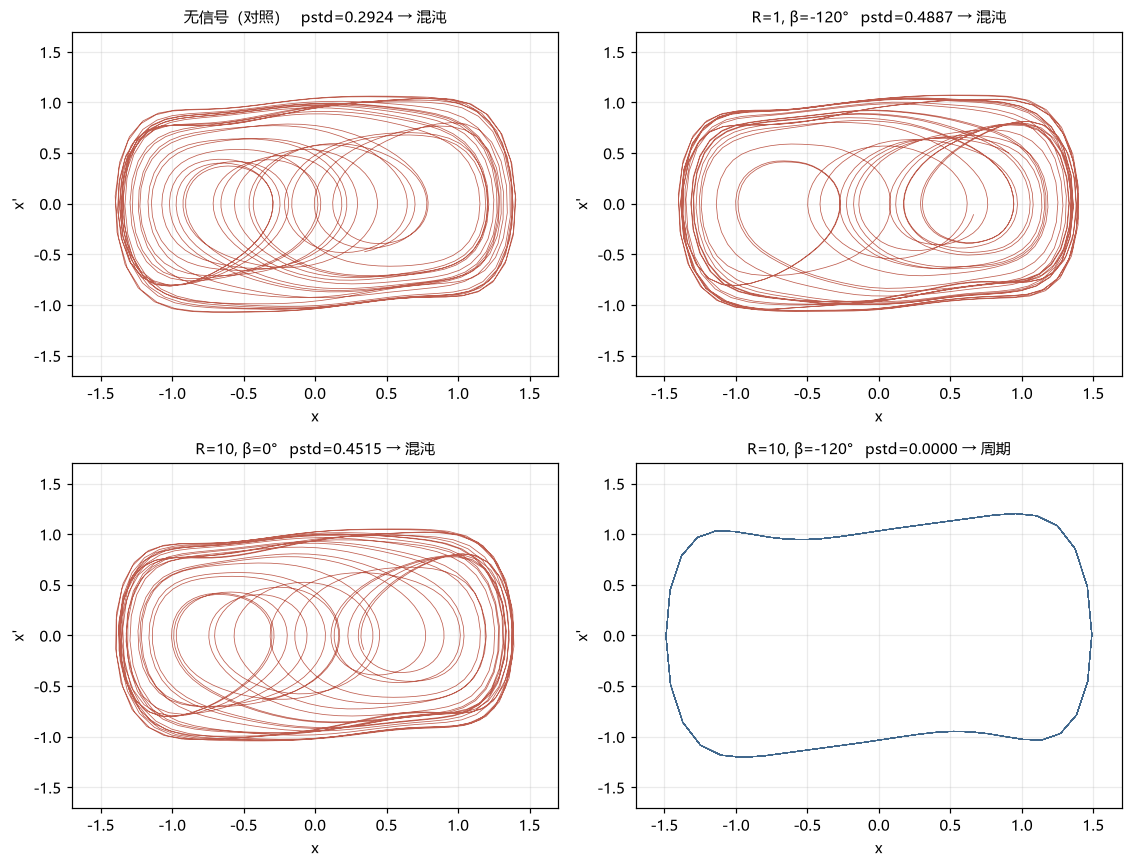

图已保存: ..\复现输出\s2-figs\s2-04-图5四幅消融.png
只有右下角（R 对了、初相也对）跳到大周期态，其余三幅全保持混沌。


In [2]:

d5 = load("fig5")
fig, ax = plt.subplots(2, 2, figsize=(10.4, 8.0))
order = [("no_signal", "无信号（对照）"), ("R1_b-120", "R=1, β=-120°"),
         ("R10_b0", "R=10, β=0°"), ("R10_b-120", "R=10, β=-120°")]
for a, (k, ttl) in zip(ax.ravel(), order):
    c = d5[k]["cur"]
    ok = d5[k]["pstd"] < 0.02
    a.plot(c["x"], c["y"], lw=.5, color="#1f4e79" if ok else "#b3402f", alpha=.85)
    a.set_title(f"{ttl}   pstd={d5[k]['pstd']:.4f} → {'周期' if ok else '混沌'}",
                fontsize=10)
    a.set_xlim(-1.7, 1.7); a.set_ylim(-1.7, 1.7)
    a.set_xlabel("x"); a.set_ylabel("x'")
plt.tight_layout(); savefig("s2-04-图5四幅消融.png")
print("只有右下角（R 对了、初相也对）跳到大周期态，其余三幅全保持混沌。")


## 相位窗口的解析边界

由 $C^2\ge0.73^2$ 解出允许的相位失配

$$\Delta_{\max}=\arccos\frac{0.73^2-0.72^2-\gamma^2}{2\times0.72\gamma}$$

$\gamma=0.02$ 代入得 $60.69°$，与原文 $60.7°$ 一致。但把它当"常数"是危险的：
$\gamma$ 降到 0.0196 以下时 $\Delta_{\max}$ 归零，三振子会出现硬盲区。
**盲区不是"噪声下才模糊"，无噪声时就已经存在。**


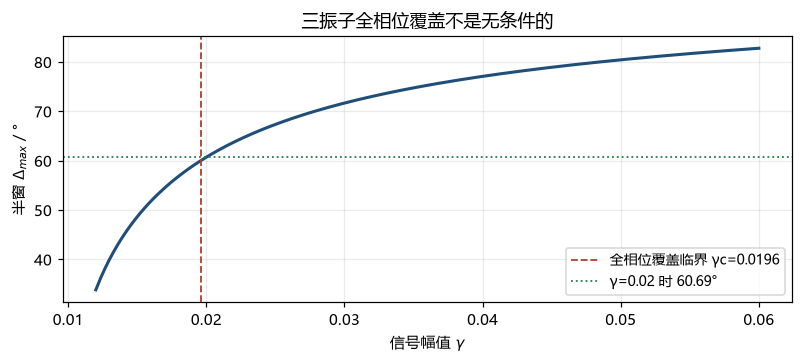

图已保存: ..\复现输出\s2-figs\s2-04-相位窗口.png
γc=0.01961；γ=0.015 时半窗 48.63°


In [3]:

g = np.linspace(0.012, 0.06, 300)
C = 0.73
arg = (C**2 - 0.72**2 - g**2) / (2*0.72*g)
win = np.degrees(np.arccos(np.clip(arg, -1, 1)))
gc = (-0.72 + np.sqrt(0.72**2 + 4*(C**2-0.72**2)))/2
fig, ax = plt.subplots(figsize=(7.4, 3.4))
ax.plot(g, win, lw=2, color="#1f4e79")
ax.axvline(gc, color="#b3402f", ls="--", lw=1.2, label=f"全相位覆盖临界 γc={gc:.4f}")
ax.axhline(60.69, color="#2e7d4f", ls=":", lw=1.2, label="γ=0.02 时 60.69°")
ax.set_xlabel(r"信号幅值 $\gamma$"); ax.set_ylabel(r"半窗 $\Delta_{max}$ / °")
ax.set_title("三振子全相位覆盖不是无条件的")
ax.legend(fontsize=9)
plt.tight_layout(); savefig("s2-04-相位窗口.png")
print(f"γc={gc:.5f}；γ=0.015 时半窗 {np.degrees(np.arccos(np.clip((C**2-0.72**2-0.015**2)/(2*0.72*0.015),-1,1))):.2f}°")
